In [1]:
import sys
print("Python version:", sys.version)

import numpy as np
import matplotlib.pyplot as plt

print("NumPy version:", np.__version__)
print("Matplotlib is working!")

Python version: 3.14.6 | packaged by Anaconda, Inc. | (main, Jul  9 2026, 14:29:05) [MSC v.1942 64 bit (AMD64)]
NumPy version: 2.4.6
Matplotlib is working!


In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Create folders for the project
project_dir = Path.cwd()

(project_dir / "input_images").mkdir(exist_ok=True)
(project_dir / "results").mkdir(exist_ok=True)
(project_dir / "screenshots").mkdir(exist_ok=True)

print("OpenCV version:", cv2.__version__)
print("Project folder:", project_dir)
print("Project folders created successfully!")

OpenCV version: 4.13.0
Project folder: C:\Users\Neha
Project folders created successfully!


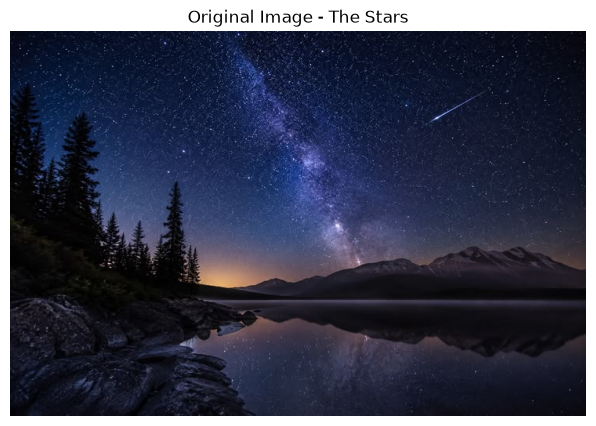

Image loaded successfully!
Image dimensions: (491, 735, 3)


In [3]:
import cv2
import matplotlib.pyplot as plt

img_path = r"C:\Users\Neha\Downloads\The Stars.jpg"

img = cv2.imread(img_path)

if img is None:
    print("Image not found. Please check the path.")
else:
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(8, 5))
    plt.imshow(img_rgb)
    plt.title("Original Image - The Stars")
    plt.axis("off")
    plt.show()

    print("Image loaded successfully!")
    print("Image dimensions:", img.shape)

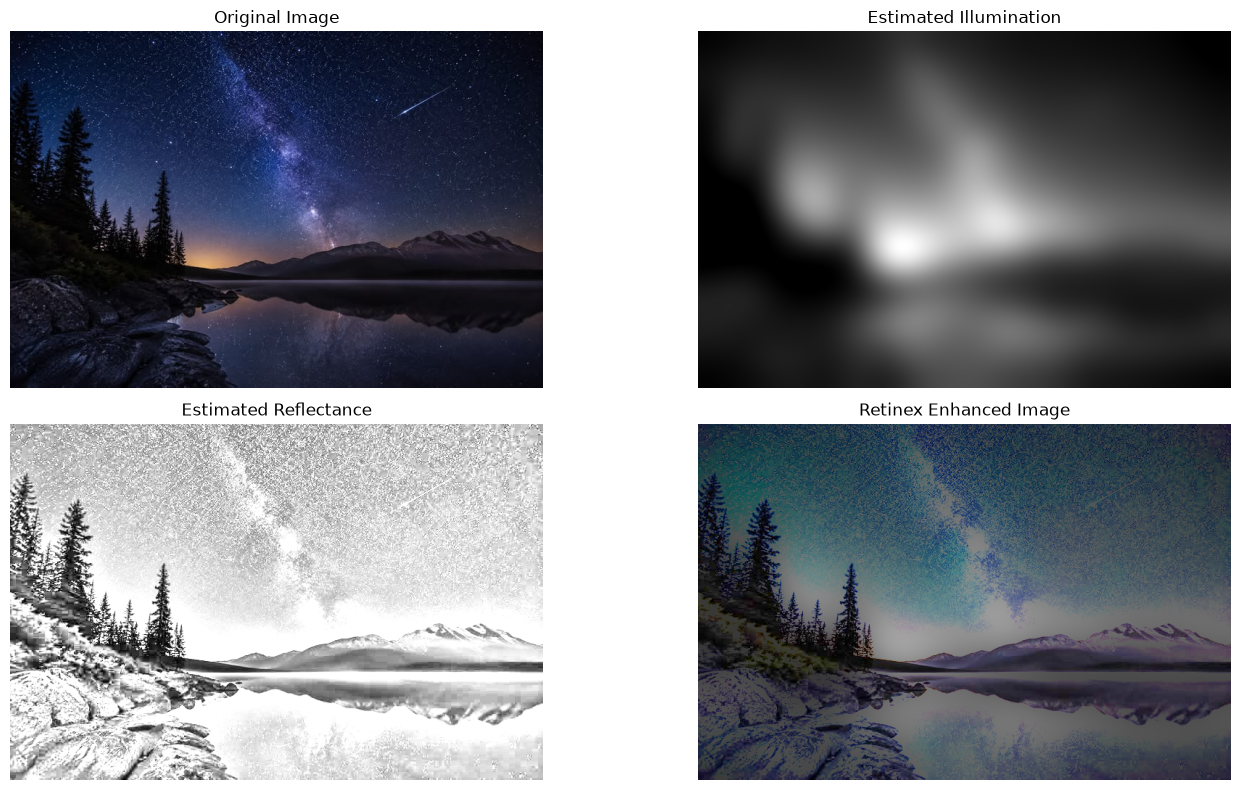

Retinex decomposition completed.
Results saved in: C:\Users\Neha\results


In [4]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

# Convert original image to RGB for display
original = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# Convert image to float values between 0 and 1
I = original.astype(np.float32) / 255.0

# Step 1: Estimate illumination using Gaussian blur
gray = cv2.cvtColor(original, cv2.COLOR_RGB2GRAY)
illumination = cv2.GaussianBlur(
    gray.astype(np.float32) / 255.0,
    (0, 0),
    sigmaX=25
)

# Prevent division by zero
illumination = np.maximum(illumination, 0.05)

# Step 2: Estimate reflectance
reflectance = I / illumination[:, :, np.newaxis]
reflectance = np.clip(reflectance, 0, 1)

# Step 3: Enhance illumination
enhanced_illumination = np.sqrt(illumination)
enhanced_illumination = np.clip(enhanced_illumination, 0, 1)

# Step 4: Reconstruct enhanced image
enhanced = reflectance * enhanced_illumination[:, :, np.newaxis]
enhanced = np.clip(enhanced, 0, 1)

# Display results
plt.figure(figsize=(15, 8))

plt.subplot(2, 2, 1)
plt.imshow(original)
plt.title("Original Image")
plt.axis("off")

plt.subplot(2, 2, 2)
plt.imshow(illumination, cmap="gray")
plt.title("Estimated Illumination")
plt.axis("off")

plt.subplot(2, 2, 3)
plt.imshow(np.mean(reflectance, axis=2), cmap="gray")
plt.title("Estimated Reflectance")
plt.axis("off")

plt.subplot(2, 2, 4)
plt.imshow(enhanced)
plt.title("Retinex Enhanced Image")
plt.axis("off")

plt.tight_layout()
plt.show()

# Save the output images
from pathlib import Path

results_dir = Path("results")
results_dir.mkdir(exist_ok=True)

cv2.imwrite(
    str(results_dir / "retinex_enhanced.png"),
    cv2.cvtColor((enhanced * 255).astype(np.uint8),
                 cv2.COLOR_RGB2BGR)
)

cv2.imwrite(
    str(results_dir / "illumination.png"),
    (illumination * 255).astype(np.uint8)
)

cv2.imwrite(
    str(results_dir / "reflectance.png"),
    (np.mean(reflectance, axis=2) * 255).astype(np.uint8)
)

print("Retinex decomposition completed.")
print("Results saved in:", results_dir.resolve())

In [5]:
import numpy as np
import cv2
import pandas as pd
from pathlib import Path

def calculate_metrics(image):
    # Convert RGB image to grayscale
    gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)

    # Average brightness
    brightness = np.mean(gray)

    # Contrast using standard deviation
    contrast = np.std(gray)

    # Entropy measures intensity distribution
    hist = cv2.calcHist([gray], [0], None, [256], [0, 256])
    probabilities = hist.ravel() / hist.sum()
    probabilities = probabilities[probabilities > 0]
    entropy = -np.sum(probabilities * np.log2(probabilities))

    return brightness, contrast, entropy

# Convert images to 8-bit format for evaluation
original_uint8 = original.astype(np.uint8)
enhanced_uint8 = (enhanced * 255).astype(np.uint8)

original_metrics = calculate_metrics(original_uint8)
enhanced_metrics = calculate_metrics(enhanced_uint8)

results_table = pd.DataFrame({
    "Metric": ["Mean Brightness (0-255)",
               "Contrast (Standard Deviation)",
               "Grayscale Entropy (bits)"],
    "Original Image": original_metrics,
    "Enhanced Image": enhanced_metrics
})

print(results_table.to_string(index=False))

# Save evaluation results
Path("results").mkdir(exist_ok=True)
results_table.to_csv("results/evaluation_metrics.csv", index=False)

print("\nEvaluation table saved successfully.")

                       Metric  Original Image  Enhanced Image
      Mean Brightness (0-255)       35.945107       73.952475
Contrast (Standard Deviation)       26.376720       32.081975
     Grayscale Entropy (bits)        6.454654        7.004646

Evaluation table saved successfully.


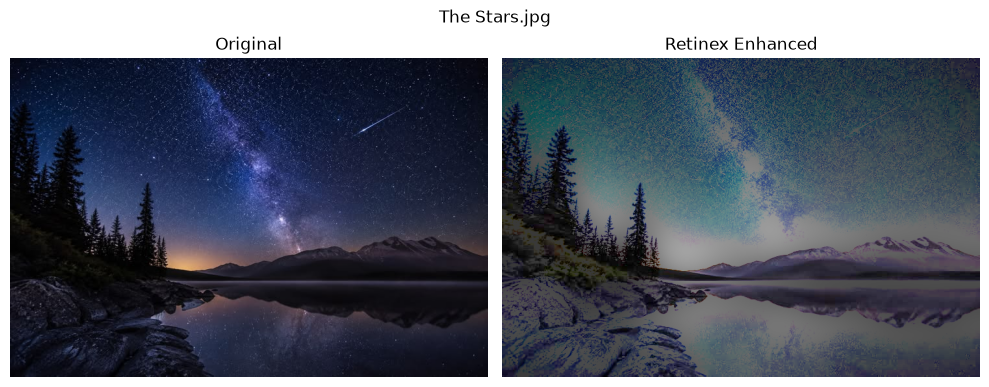

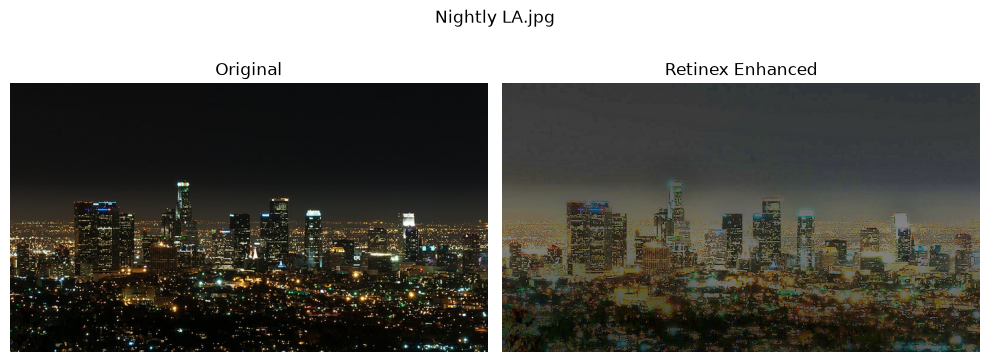

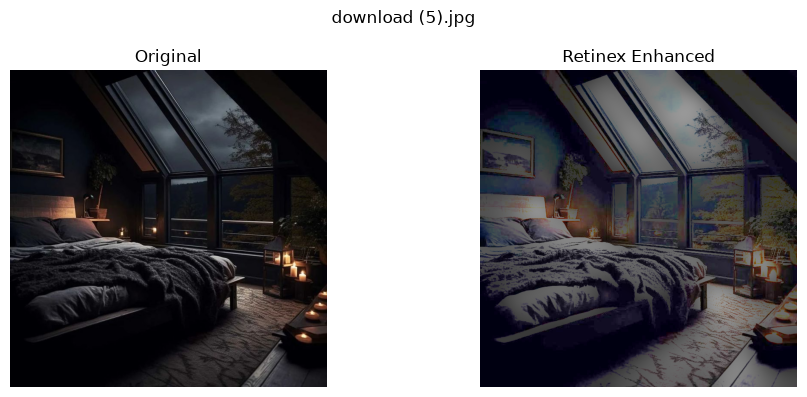

,Image,Original Brightness,Enhanced Brightness,Original Contrast,Enhanced Contrast,Original Entropy,Enhanced Entropy
0,The Stars.jpg,35.945,73.952,26.377,32.082,6.455,7.005
1,Nightly LA.jpg,29.971,64.068,35.207,27.643,5.906,6.460
2,download (5).jpg,27.471,53.994,32.321,40.627,6.102,6.633


Experiment completed. Results saved to: C:\Users\Neha\results


In [6]:
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

image_paths = [
    r"C:\Users\Neha\Downloads\The Stars.jpg",
    r"C:\Users\Neha\Downloads\Nightly LA.jpg",
    r"C:\Users\Neha\Downloads\download (5).jpg"
]

results_dir = Path("results")
results_dir.mkdir(exist_ok=True)

def retinex_enhance(image):
    original_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    I = original_rgb.astype(np.float32) / 255.0

    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    illumination = cv2.GaussianBlur(
        gray.astype(np.float32) / 255.0,
        (0, 0), sigmaX=25
    )
    illumination = np.maximum(illumination, 0.05)

    reflectance = I / illumination[:, :, np.newaxis]
    reflectance = np.clip(reflectance, 0, 1)

    enhanced_illumination = np.sqrt(illumination)
    enhanced = reflectance * enhanced_illumination[:, :, np.newaxis]
    enhanced = np.clip(enhanced, 0, 1)

    return original_rgb, illumination, reflectance, enhanced

def calculate_metrics(rgb_image):
    gray = cv2.cvtColor(rgb_image, cv2.COLOR_RGB2GRAY)
    brightness = float(np.mean(gray))
    contrast = float(np.std(gray))

    hist = cv2.calcHist([gray], [0], None, [256], [0, 256]).ravel()
    p = hist / hist.sum()
    p = p[p > 0]
    entropy = float(-np.sum(p * np.log2(p)))

    return brightness, contrast, entropy

rows = []

for index, path in enumerate(image_paths, start=1):
    image = cv2.imread(path)

    if image is None:
        print("Could not load:", path)
        continue

    original_rgb, illum, refl, enhanced = retinex_enhance(image)
    enhanced_u8 = (enhanced * 255).astype(np.uint8)

    # Save enhanced output
    output_path = results_dir / f"enhanced_image_{index}.png"
    cv2.imwrite(
        str(output_path),
        cv2.cvtColor(enhanced_u8, cv2.COLOR_RGB2BGR)
    )

    original_metrics = calculate_metrics(original_rgb)
    enhanced_metrics = calculate_metrics(enhanced_u8)

    rows.append({
        "Image": Path(path).name,
        "Original Brightness": original_metrics[0],
        "Enhanced Brightness": enhanced_metrics[0],
        "Original Contrast": original_metrics[1],
        "Enhanced Contrast": enhanced_metrics[1],
        "Original Entropy": original_metrics[2],
        "Enhanced Entropy": enhanced_metrics[2]
    })

    # Display original and enhanced images
    plt.figure(figsize=(10, 4))

    plt.subplot(1, 2, 1)
    plt.imshow(original_rgb)
    plt.title("Original")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(enhanced_u8)
    plt.title("Retinex Enhanced")
    plt.axis("off")

    plt.suptitle(Path(path).name)
    plt.tight_layout()
    plt.show()

if rows:
    comparison = pd.DataFrame(rows)
    display(comparison.round(3))
    comparison.to_csv(
        results_dir / "multi_image_comparison.csv",
        index=False
    )
    print("Experiment completed. Results saved to:", results_dir.resolve())
else:
    print("No images were processed. Check the file paths.")

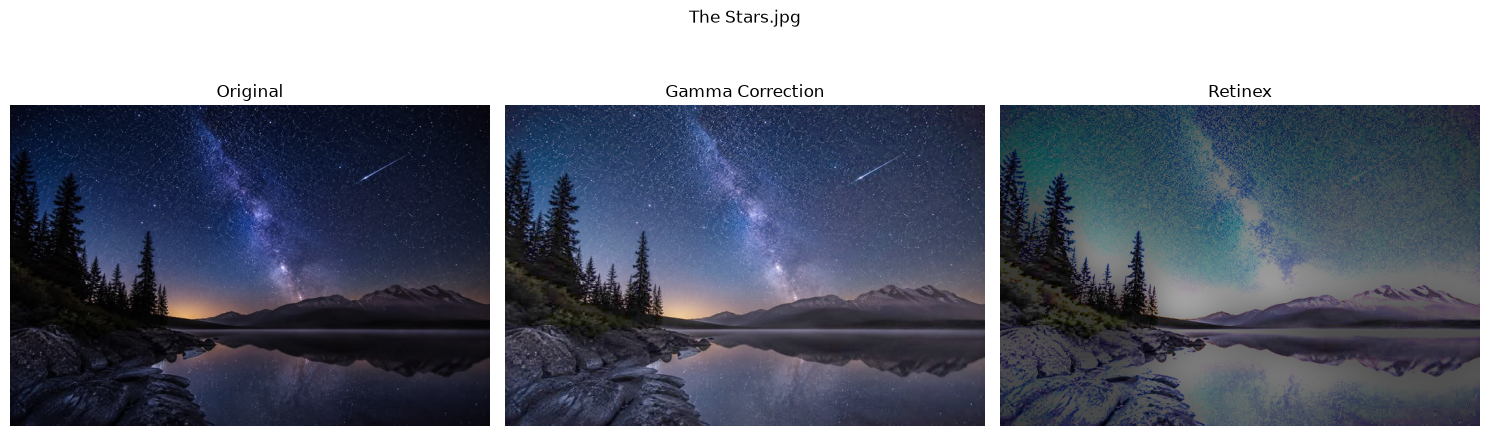

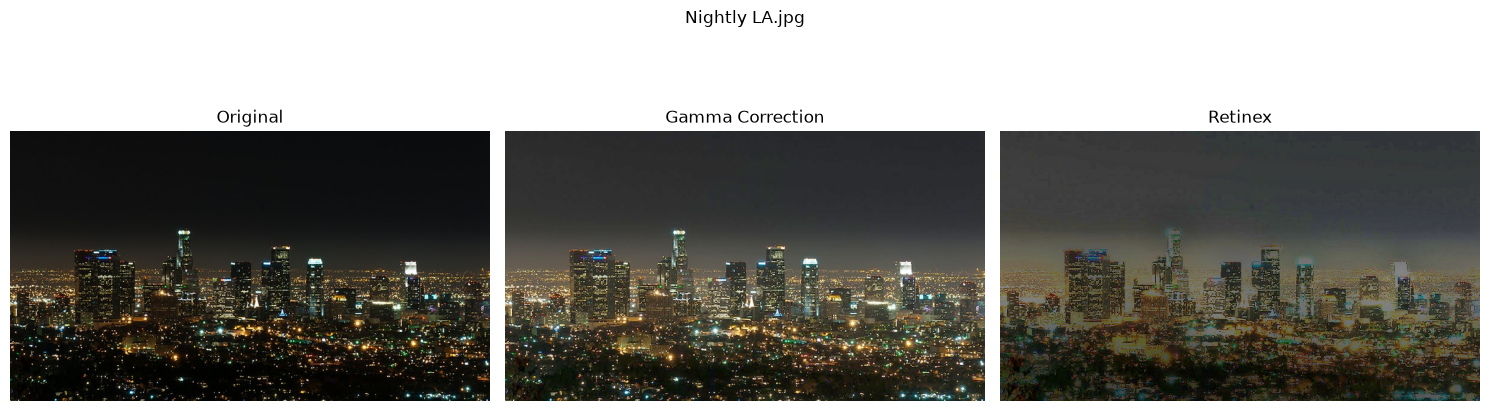

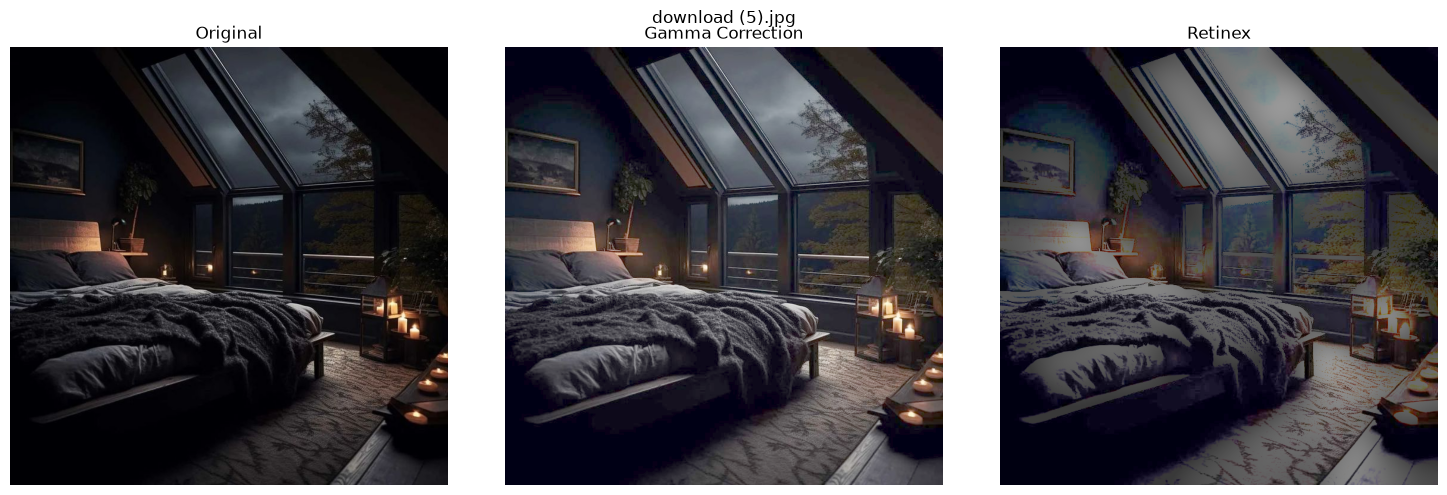

,Image,Method,Brightness,Contrast,Entropy
0,The Stars.jpg,Original,35.945,26.377,6.455
1,The Stars.jpg,Gamma Correction,72.705,33.168,6.994
2,The Stars.jpg,Retinex,73.952,32.082,7.005
3,Nightly LA.jpg,Original,29.971,35.207,5.906
4,Nightly LA.jpg,Gamma Correction,62.940,38.280,6.452
5,Nightly LA.jpg,Retinex,64.068,27.643,6.460
6,download (5).jpg,Original,27.471,32.321,6.102
7,download (5).jpg,Gamma Correction,55.790,43.835,6.630
8,download (5).jpg,Retinex,53.994,40.627,6.633


Comparison figures and metrics saved successfully.


In [8]:
from pathlib import Path
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

comparison_rows = []
results_dir = Path("results")
results_dir.mkdir(exist_ok=True)

for path in image_paths:
    bgr = cv2.imread(path)

    if bgr is None:
        print("Skipping unreadable image:", path)
        continue

    original_rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)

    # Baseline: gamma correction
    gamma = 0.6
    gamma_img = np.power(
        original_rgb.astype(np.float32) / 255.0,
        gamma
    )
    gamma_img = np.clip(gamma_img * 255, 0, 255).astype(np.uint8)

    # Retinex enhancement
    _, illumination, reflectance, retinex_float = retinex_enhance(bgr)
    retinex_img = np.clip(
        retinex_float * 255, 0, 255
    ).astype(np.uint8)

    # Display all three methods
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    axes[0].imshow(original_rgb)
    axes[0].set_title("Original")
    axes[1].imshow(gamma_img)
    axes[1].set_title("Gamma Correction")
    axes[2].imshow(retinex_img)
    axes[2].set_title("Retinex")

    for ax in axes:
        ax.axis("off")

    fig.suptitle(Path(path).name)
    plt.tight_layout()
    plt.savefig(
        results_dir / f"{Path(path).stem}_method_comparison.png",
        dpi=200,
        bbox_inches="tight"
    )
    plt.show()

    for method, result in [
        ("Original", original_rgb),
        ("Gamma Correction", gamma_img),
        ("Retinex", retinex_img)
    ]:
        brightness, contrast, entropy = calculate_metrics(result)
        comparison_rows.append({
            "Image": Path(path).name,
            "Method": method,
            "Brightness": brightness,
            "Contrast": contrast,
            "Entropy": entropy
        })

comparison_df = pd.DataFrame(comparison_rows)
display(comparison_df.round(3))

comparison_df.to_csv(
    results_dir / "method_comparison_metrics.csv",
    index=False
)

print("Comparison figures and metrics saved successfully.")